# Live coding 01 · From gradients to a trained network in PyTorch

The coach's notebook for lecture sections 6–8 (gradient descent and optimizers · the training loop ·
generalization and debugging), plus a short bridge to the inversion task.

* Run it **cell by cell**. The saved outputs are the numbers to expect (CPU, one thread; another machine may differ in the 3rd decimal).
* At every **PREDICT** cell, stop and take a public vote, then run the next cell.
* Planned mistakes: **1** no input scaling (part 4) · **2** no `zero_grad` (part 6) · **3** Sigmoid + `BCEWithLogitsLoss`, the cliffhanger (part 7) · **4** target shape (part 8).
* The whole notebook runs in about a minute.
* **Colab:** upload `data_train.csv` in the Files panel and set `DATA_DIR = "."` in the first code cell.

| Part | What | Lecture |
|---|---|---|
| 0 | Setup and seed | |
| 1 | Tensors, layers, shapes; the 2-8-8-1 has 105 parameters | §2 recap |
| 2 | Gradient descent by hand, then with `torch.optim` | §6 |
| 3 | Kobe's shots: shapes, base rate, train/validation split | §7 |
| 4 | Planned mistake 1: no input scaling | §7.4 |
| 5 | The model, the five-beat loop, evaluation, baselines, pictures | §7.5–7.6, §7.11 |
| 6 | Planned mistake 2: no `zero_grad` | §7.7 |
| 7 | Planned mistake 3: Sigmoid + `BCEWithLogitsLoss` (cliffhanger reveal) | §7.8 |
| 8 | Planned mistake 4: target shape `(N,)` vs `(N, 1)` | §7.9 |
| 9 | Optimizer comparison on Kobe | §6.10 |
| 10 | Overfitting and early stopping | §8.2–8.4 |
| 11 | Optimise the input, not the weights: bridge to the inversion task | §9.8–9.10 |

## Part 0 · Setup

In [1]:
import math

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn as nn

DATA_DIR = "../data/kobe"          # Colab: upload data_train.csv and use DATA_DIR = "."

torch.set_num_threads(1)           # tiny networks run fastest on one thread
torch.manual_seed(0)               # same seed -> same initial weights -> the same numbers as below
pd.set_option("display.precision", 4)
print(torch.__version__)

2.15.0+cpu


## Part 1 · Tensors, layers and shapes

A layer is a matrix multiply applied to a whole batch at once.

**PREDICT:** `nn.Linear(2, 8)` on a batch of 32 shots. Shape of the output? Shape of `layer.weight`?

In [2]:
layer = nn.Linear(2, 8)            # 2 inputs (x, y) -> 8 neurons
batch = torch.randn(32, 2)         # 32 shots, 2 numbers each
out = layer(batch)

print("batch ", batch.shape)
print("weight", layer.weight.shape, "  <- (out, in), not (in, out)")
print("bias  ", layer.bias.shape)
print("output", out.shape)

batch  torch.Size([32, 2])
weight torch.Size([8, 2])   <- (out, in), not (in, out)
bias   torch.Size([8])
output torch.Size([32, 8])


In [3]:
# nn.Linear is exactly  x @ W.T + b , for all 32 rows at once
by_hand = batch @ layer.weight.T + layer.bias
torch.allclose(by_hand, out)

True

Stack three layers: the 2-8-8-1 MLP from section 2, written as our own `nn.Module`.
Kobe rules: at most 3 linear layers, at most 8 neurons each, activations as modules after linear layers,
**no `nn.Sequential`** (it scores 0). The last layer outputs a **logit**, with no sigmoid: the loss adds it.

In [4]:
class MLP(nn.Module):
    def __init__(self, hidden=8):
        super().__init__()
        # __init__ creates the layers: this is where the weights live
        self.fc1 = nn.Linear(2, hidden)
        self.act1 = nn.ReLU()
        self.fc2 = nn.Linear(hidden, hidden)
        self.act2 = nn.ReLU()
        self.fc3 = nn.Linear(hidden, 1)        # one logit out, no sigmoid

    def forward(self, x):
        # forward says how a batch flows through the layers
        x = self.act1(self.fc1(x))             # (B, 2) -> (B, 8)
        x = self.act2(self.fc2(x))             # (B, 8) -> (B, 8)
        return self.fc3(x)                     # (B, 8) -> (B, 1)

**PREDICT:** how many parameters (weights + biases) does the 2-8-8-1 have?

In [5]:
model = MLP()
for name, p in model.named_parameters():
    print(f"{name:11s} {str(tuple(p.shape)):7s} {p.numel():3d}")
print("total", sum(p.numel() for p in model.parameters()))     # 24 + 72 + 9
print("output for the batch:", model(batch).shape)

fc1.weight  (8, 2)   16
fc1.bias    (8,)      8
fc2.weight  (8, 8)   64
fc2.bias    (8,)      8
fc3.weight  (1, 8)    8
fc3.bias    (1,)      1
total 105
output for the batch: torch.Size([32, 1])


## Part 2 · Gradient descent: by hand, then with `torch.optim`

On paper: L(w) = (w − 3)², w₀ = 0, η = 0.1 → gradient −6 → w₁ = 0.6. Now autograd computes the gradient.
Four new words: `requires_grad` (track this number) · `backward()` (fill `.grad`) ·
`torch.no_grad()` (update without recording) · `grad.zero_()` (clear before the next step).

In [6]:
w = torch.tensor(0.0, requires_grad=True)      # track gradients for w
for step in range(5):
    loss = (w - 3) ** 2
    loss.backward()                            # dL/dw = 2(w - 3), stored in w.grad
    print(f"step {step}: w = {w.item():.4f}   loss = {loss.item():.4f}   grad = {w.grad.item():.4f}")
    with torch.no_grad():                      # the update itself must not be recorded in the graph
        w -= 0.1 * w.grad
    w.grad.zero_()                             # gradients ADD UP, so clear them before the next backward
print(f"after 5 steps: w = {w.item():.4f}")

step 0: w = 0.0000   loss = 9.0000   grad = -6.0000
step 1: w = 0.6000   loss = 5.7600   grad = -4.8000
step 2: w = 1.0800   loss = 3.6864   grad = -3.8400
step 3: w = 1.4640   loss = 2.3593   grad = -3.0720
step 4: w = 1.7712   loss = 1.5099   grad = -2.4576
after 5 steps: w = 2.0170


The same thing with an optimizer: the three lines `zero_grad` · `backward` · `step`.

In [7]:
w = torch.tensor(0.0, requires_grad=True)
opt = torch.optim.SGD([w], lr=0.1)             # the optimizer gets the list of tensors it may change
for step in range(5):
    opt.zero_grad()
    loss = (w - 3) ** 2
    loss.backward()
    opt.step()                                 # does  w -= lr * w.grad  for us
print(f"after 5 steps: w = {w.item():.4f}")    # identical to the manual loop

after 5 steps: w = 2.0170


**PREDICT:** learning rates 0.02, 0.3, 0.9 and 1.05. Where is w after 10 steps? (The minimum is at 3.)

In [8]:
for lr in [0.02, 0.3, 0.9, 1.05]:
    w = torch.tensor(0.0, requires_grad=True)
    opt = torch.optim.SGD([w], lr=lr)
    path = []
    for step in range(10):
        opt.zero_grad()
        loss = (w - 3) ** 2
        loss.backward()
        opt.step()
        path.append(round(w.item(), 2))
    print(f"lr {lr:<4}  w: {path}")

lr 0.02  w: [0.12, 0.24, 0.35, 0.45, 0.55, 0.65, 0.75, 0.84, 0.92, 1.01]
lr 0.3   w: [1.8, 2.52, 2.81, 2.92, 2.97, 2.99, 3.0, 3.0, 3.0, 3.0]
lr 0.9   w: [5.4, 1.08, 4.54, 1.77, 3.98, 2.21, 3.63, 2.5, 3.4, 2.68]
lr 1.05  w: [6.3, -0.63, 6.99, -1.39, 7.83, -2.31, 8.85, -3.43, 10.07, -4.78]


Too slow · just right · oscillating but converging · diverging. The error is multiplied by (1 − 2·lr) every step.

**PREDICT (P7):** one step of Adam with lr 1e-3 on three weights whose gradients are 1000, 1 and 0.001.
How far does each weight move? And with plain SGD?

In [9]:
grads = torch.tensor([1000.0, 1.0, 0.001])
for opt_class in [torch.optim.SGD, torch.optim.Adam]:
    w = torch.zeros(3, requires_grad=True)
    opt = opt_class([w], lr=1e-3)
    loss = (grads * w).sum()                   # so dL/dw is exactly `grads`
    loss.backward()
    opt.step()
    moves = [f"{v:.6f}" for v in w.tolist()]
    print(f"{opt_class.__name__:4s} moved the weights by {moves}")

SGD  moved the weights by ['-1.000000', '-0.001000', '-0.000001']
Adam moved the weights by ['-0.001000', '-0.001000', '-0.001000']


SGD's step is lr × gradient. Adam's first step is ≈ lr for **every** weight, whatever the gradient's size.

## Part 3 · Kobe's shots

`loc_x`, `loc_y` are in tenths of feet with the rim at (0, 0). They are the **only** allowed inputs
(`shot_distance` is forbidden, and it is just ⌊distance / 10⌋ anyway).

**PREDICT:** what percentage of his shots went in?

In [10]:
df = pd.read_csv(f"{DATA_DIR}/data_train.csv")
print(df.shape)
df.head()

(25000, 6)


,loc_x,loc_y,minutes_remaining,shot_distance,shot_made_flag,shot_id
0,0,0,7,0,1,1
1,-3,130,9,13,0,2
2,82,8,7,8,0,3
3,100,101,10,14,1,4
4,0,0,9,0,1,5


In [11]:
made_rate = df["shot_made_flag"].mean()
print(f"shots made: {made_rate:.1%}   ->   'always miss' is already {1 - made_rate:.1%} accurate")
df[["loc_x", "loc_y"]].describe()

shots made: 44.7%   ->   'always miss' is already 55.3% accurate


,loc_x,loc_y
count,25000.0000,25000.0000
mean,7.1254,91.2879
std,110.0299,88.2893
min,-250.0000,-44.0000
25%,-67.2500,4.0000
50%,0.0000,72.0000
75%,94.0000,160.0000
max,248.0000,791.0000


Raw coordinates in the hundreds: remember that for part 4.

**PREDICT:** the model outputs shape `(B, 1)`. What shape must the targets `y` have for `BCEWithLogitsLoss`?

In [12]:
from sklearn.model_selection import train_test_split

X = df[["loc_x", "loc_y"]].values.astype("float32")
y = df["shot_made_flag"].values.astype("float32")
# 80/20 split; the fixed random_state gives the same split on every run
X_train, X_val, y_train, y_val = train_test_split(X, y, test_size=0.2, random_state=0)

X_train = torch.from_numpy(X_train)
X_val = torch.from_numpy(X_val)
y_train = torch.from_numpy(y_train).view(-1, 1)    # (N,) -> (N, 1): the same shape as the model output
y_val = torch.from_numpy(y_val).view(-1, 1)

print("X_train", X_train.shape, "  y_train", y_train.shape)
print("X_val  ", X_val.shape, "  y_val  ", y_val.shape)
print(f"made rate: train {y_train.mean():.3f}, validation {y_val.mean():.3f}")
print("steps per epoch with batch 64:", math.ceil(len(X_train) / 64), "  last batch:", len(X_train) % 64)

X_train torch.Size([20000, 2])   y_train torch.Size([20000, 1])
X_val   torch.Size([5000, 2])   y_val   torch.Size([5000, 1])
made rate: train 0.447, validation 0.448
steps per epoch with batch 64: 313   last batch: 32


A picture of the data first (Karpathy: look at your data). The court helper is reused in part 5.

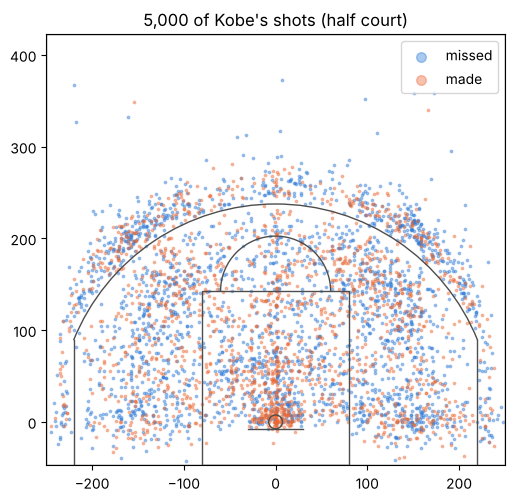

In [13]:
from matplotlib.patches import Arc, Circle, Rectangle


def draw_court(ax):
    # NBA half court in tenths of feet, rim at (0, 0)
    ink = dict(edgecolor="0.3", lw=1, fill=False)
    ax.add_patch(Circle((0, 0), 7.5, **ink))                                   # rim
    ax.plot([-30, 30], [-7.5, -7.5], color="0.3", lw=1)                         # backboard
    ax.add_patch(Rectangle((-80, -47.5), 160, 190, **ink))                     # paint
    ax.add_patch(Arc((0, 142.5), 120, 120, theta1=0, theta2=180, **ink))       # free-throw circle
    ax.plot([-220, -220], [-47.5, 89.5], color="0.3", lw=1)                     # corner threes
    ax.plot([220, 220], [-47.5, 89.5], color="0.3", lw=1)
    ax.add_patch(Arc((0, 0), 475, 475, theta1=22, theta2=158, **ink))          # three-point arc, 23.75 ft
    ax.add_patch(Rectangle((-250, -47.5), 500, 470, **ink))                    # baseline, sidelines, half-way line
    ax.set_xlim(-250, 250)
    ax.set_ylim(-47.5, 422.5)
    ax.set_aspect("equal")


shots = df.sample(5000, random_state=0)
fig, ax = plt.subplots(figsize=(6, 5.6))
for flag, color, label in [(0, "#2a78d6", "missed"), (1, "#eb6834", "made")]:
    subset = shots[shots["shot_made_flag"] == flag]
    ax.scatter(subset["loc_x"], subset["loc_y"], s=3, alpha=0.4, color=color, label=label)
draw_court(ax)
ax.legend(loc="upper right", markerscale=4)
ax.set_title("5,000 of Kobe's shots (half court)")
plt.show()

## Part 4 · Planned mistake 1: no input scaling

We feed the **raw** coordinates (hundreds) into a fresh 2-8-8-1 and look at the loss before any training.
A fresh net should start near ln 2 = 0.693 (Kobe's constant baseline is 0.687).

**PREDICT: what will happen?** Loss at init: (a) ≈ 0.69 (b) ≈ 2 (c) NaN (d) an error

In [14]:
loss_fn = nn.BCEWithLogitsLoss()           # sigmoid + binary cross-entropy in one numerically safe step

torch.manual_seed(0)
model = MLP()
with torch.no_grad():
    logits = model(X_train)                # RAW coordinates
print(f"loss at init, raw inputs: {loss_fn(logits, y_train).item():.3f}    (ln 2 = {math.log(2):.3f})")
print(f"logits range: {logits.min().item():.1f} to {logits.max().item():.1f}")

loss at init, raw inputs: 2.323    (ln 2 = 0.693)
logits range: -37.8 to -0.1


Inputs in the hundreds → pre-activations in the hundreds → logits of ±tens → the net is confidently wrong
from step 0. Fix: standardise each column with the **training** mean and std (LeCun 1998, "Efficient BackProp").
Validation and test data reuse the same two numbers.
Kobe task: the grader feeds raw coordinates, so in your submission the scaling must be folded into `fc1` (section 9).

In [15]:
mu = X_train.mean(0)                       # one mean and one std per column (x, y)
sd = X_train.std(0)
X_train_s = (X_train - mu) / sd
X_val_s = (X_val - mu) / sd                # TRAIN statistics, never the validation set's own
print("train mean", mu, "  train std", sd)
print("scaled train mean", X_train_s.mean(0), "  scaled train std", X_train_s.std(0))

train mean tensor([ 7.6390, 91.2753])   train std tensor([110.1732,  88.1617])
scaled train mean tensor([-2.9707e-08,  2.3651e-08])   scaled train std tensor([1., 1.])


In [16]:
with torch.no_grad():
    logits = model(X_train_s)              # the same weights, scaled inputs
print(f"loss at init, scaled inputs: {loss_fn(logits, y_train).item():.3f}")
print(f"logits range: {logits.min().item():.2f} to {logits.max().item():.2f}")

loss at init, scaled inputs: 0.691
logits range: -0.55 to -0.08


## Part 5 · The model and the training loop

Evaluation first: `model.eval()` + `torch.no_grad()`. A logit > 0 means p > 0.5, so that is the
"made" prediction; the log loss is the same `BCEWithLogitsLoss`.

In [17]:
def evaluate(model, X, y):
    model.eval()                           # inference behaviour (matters for dropout / batch-norm): a habit
    with torch.no_grad():                  # no graph: faster, less memory
        logits = model(X)
    log_loss = loss_fn(logits, y).item()
    accuracy = ((logits > 0).float() == y).float().mean().item()     # logit > 0  <=>  p > 0.5
    return log_loss, accuracy


evaluate(model, X_val_s, y_val)            # the untrained net from part 4

(0.6904754042625427, 0.5523999929428101)

The five beats: **zero_grad → forward → loss → backward → step**. We wrap the loop in a function
because we will train eight more models today.

In [18]:
def train(model, opt, epochs=30):
    history = []
    for epoch in range(epochs):
        model.train()
        for idx in torch.randperm(len(X_train_s)).split(64):   # shuffle, then 313 mini-batches of 64
            opt.zero_grad()                                    # 1. clear the old gradients
            logits = model(X_train_s[idx])                     # 2. forward
            loss = loss_fn(logits, y_train[idx])               # 3. loss
            loss.backward()                                    # 4. backward: fills p.grad for every weight
            opt.step()                                         # 5. step: update the weights
        train_loss = evaluate(model, X_train_s, y_train)[0]
        val_loss = evaluate(model, X_val_s, y_val)[0]
        history.append([train_loss, val_loss])
    return pd.DataFrame(history, columns=["train loss", "val loss"], index=range(1, epochs + 1))

**PREDICT:** after 30 epochs (9,390 steps), will we beat the constant baseline 0.687? By how much? Accuracy?

In [19]:
torch.manual_seed(0)
model = MLP()
opt = torch.optim.Adam(model.parameters(), lr=1e-3)
history = train(model, opt)
history.iloc[[0, 4, 9, 19, 29]]            # epochs 1, 5, 10, 20, 30

,train loss,val loss
1,0.6719,0.6740
5,0.6672,0.6666
10,0.6659,0.6658
20,0.6641,0.6645
30,0.6633,0.6641


In [20]:
val_loss, val_acc = evaluate(model, X_val_s, y_val)
print(f"MLP 2-8-8-1: val log loss {val_loss:.4f}, val accuracy {val_acc:.1%}")

MLP 2-8-8-1: val log loss 0.6641, val accuracy 60.8%


Is that good? Compare with two baselines: the constant prediction (every shot gets the training make rate)
and logistic regression, which is a network with no hidden layer: `nn.Linear(2, 1)`.

In [21]:
p_const = torch.full_like(y_val, y_train.mean().item())        # the same probability for every shot
const_loss = nn.functional.binary_cross_entropy(p_const, y_val).item()
const_acc = (y_val == 0).float().mean().item()                 # 'always miss'

torch.manual_seed(0)
logreg = nn.Linear(2, 1)                                       # logistic regression = one neuron
train(logreg, torch.optim.Adam(logreg.parameters(), lr=1e-3), epochs=10)
logreg_loss, logreg_acc = evaluate(logreg, X_val_s, y_val)

baselines = pd.DataFrame(
    {"val log loss": [const_loss, logreg_loss, val_loss], "val accuracy": [const_acc, logreg_acc, val_acc]},
    index=["constant / always miss", "logistic regression (3 params)", "MLP 2-8-8-1 (105 params)"],
)
baselines

,val log loss,val accuracy
constant / always miss,0.6876,0.5524
logistic regression (3 params),0.6781,0.5726
MLP 2-8-8-1 (105 params),0.6641,0.6080


Small but real gains: typical for noisy human data. The loss curves:

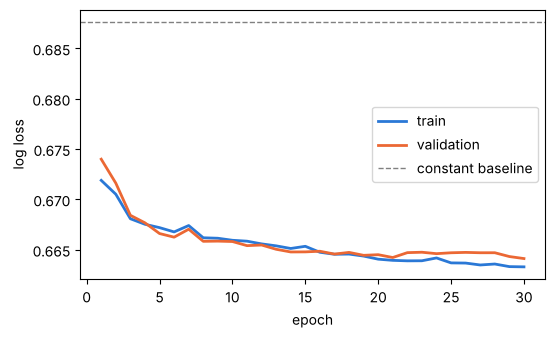

In [22]:
fig, ax = plt.subplots(figsize=(6, 3.5))
ax.plot(history.index, history["train loss"], color="#2a78d6", lw=2, label="train")
ax.plot(history.index, history["val loss"], color="#eb6834", lw=2, label="validation")
ax.axhline(const_loss, color="0.5", ls="--", lw=1, label="constant baseline")
ax.set_xlabel("epoch")
ax.set_ylabel("log loss")
ax.legend()
plt.show()

What did it learn? Its probability at every point of the court (the orange line is p = 0.5):

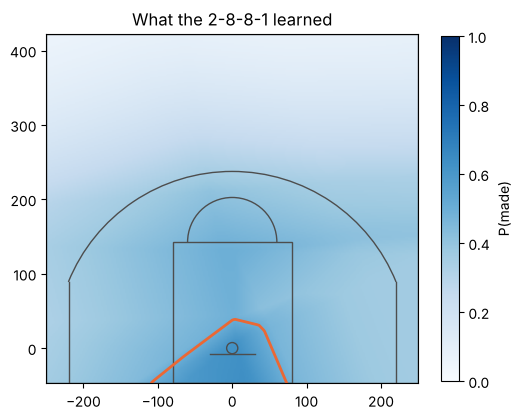

predicted probability ranges from 0.054 to 0.637


In [23]:
xs = torch.linspace(-250, 250, 251)
ys = torch.linspace(-47.5, 422.5, 236)
gx, gy = torch.meshgrid(xs, ys, indexing="xy")              # each (236, 251)
grid = torch.stack([gx.flatten(), gy.flatten()], dim=1)     # (59236, 2) raw court coordinates

model.eval()
with torch.no_grad():
    prob = torch.sigmoid(model((grid - mu) / sd)).view(gx.shape)   # the same scaling as in training

fig, ax = plt.subplots(figsize=(6, 5.6))
im = ax.imshow(prob, origin="lower", extent=(-250, 250, -47.5, 422.5), cmap="Blues", vmin=0, vmax=1)
ax.contour(gx, gy, prob, levels=[0.5], colors="#eb6834", linewidths=2)
draw_court(ax)
fig.colorbar(im, ax=ax, label="P(made)", shrink=0.8)
ax.set_title("What the 2-8-8-1 learned")
plt.show()
print(f"predicted probability ranges from {prob.min():.3f} to {prob.max():.3f}")

It never says more than ~60%, and it predicts "made" only right at the rim: that is all the accuracy metric
can reward on this data.

## Part 6 · Planned mistake 2: no `zero_grad`

The same loop with one line deleted.

**PREDICT: what will happen?** (a) crash (b) the same result (c) a worse model (d) NaN

In [24]:
torch.manual_seed(0)
model_nz = MLP()
opt = torch.optim.Adam(model_nz.parameters(), lr=1e-3)
for epoch in range(30):
    model_nz.train()
    for idx in torch.randperm(len(X_train_s)).split(64):
        # opt.zero_grad()                  <- MISTAKE 2: deleted
        loss = loss_fn(model_nz(X_train_s[idx]), y_train[idx])
        loss.backward()
        opt.step()

nz_loss, nz_acc = evaluate(model_nz, X_val_s, y_val)
print(f"no zero_grad: val log loss {nz_loss:.4f}, accuracy {nz_acc:.1%}   (always miss: {const_acc:.1%})")
with torch.no_grad():
    share_made = (model_nz(X_val_s) > 0).float().mean()
print(f"share of validation shots predicted 'made': {share_made:.1%}")

no zero_grad: val log loss 0.7015, accuracy 44.8%   (always miss: 55.2%)
share of validation shots predicted 'made': 100.0%


No error, no NaN, just a model worse than the constant baseline: a silent bug. Why? `.grad` is a running **sum**:

In [25]:
w = torch.tensor(1.0, requires_grad=True)
for i in range(3):
    loss = 2 * w
    loss.backward()
    print("w.grad =", w.grad.item())       # 2, 4, 6: every backward() ADDS to .grad

w.grad = 2.0
w.grad = 4.0
w.grad = 6.0


Without `zero_grad`, step k follows the sum of all k gradients so far, so the net keeps marching in old directions.

## Part 7 · Planned mistake 3: Sigmoid + `BCEWithLogitsLoss` (the cliffhanger)

Before the break you voted. Someone thinks "the output should be a probability" and adds `nn.Sigmoid()` as
the last layer, but keeps `BCEWithLogitsLoss`.

**PREDICT: what will happen?** (a) crash (b) normal (c) quietly worse (d) NaN. Re-vote now.

In [26]:
class SigmoidMLP(MLP):
    def __init__(self):
        super().__init__()
        self.out = nn.Sigmoid()                # <- MISTAKE 3: "the output should be a probability"

    def forward(self, x):
        return self.out(super().forward(x))    # MLP's logit squashed into (0, 1)


torch.manual_seed(0)
model_sig = SigmoidMLP()
history_sig = train(model_sig, torch.optim.Adam(model_sig.parameters(), lr=1e-3))
history_sig.iloc[[0, 4, 9, 19, 29]]

,train loss,val loss
1,0.6972,0.6975
5,0.6874,0.6869
10,0.6857,0.6852
20,0.6854,0.6850
30,0.6854,0.6849


No crash, and the printed losses look like a normal, slightly weak run. Its author treats the outputs as probabilities, so accuracy means p > 0.5:

In [27]:
model_sig.eval()
with torch.no_grad():
    p_sig = model_sig(X_val_s)                 # what this model calls probabilities
acc_sig = ((p_sig > 0.5).float() == y_val).float().mean()
print(f"printed val loss {loss_fn(p_sig, y_val).item():.4f},  accuracy {acc_sig:.1%}")

printed val loss 0.6849,  accuracy 60.9%


Looks fine. Now the **real** log loss of those probabilities, the number any grader would compute:

In [28]:
from sklearn.metrics import log_loss

with torch.no_grad():
    p_good = torch.sigmoid(model(X_val_s))     # the correct model from part 5

extreme_sig = ((p_sig < 0.01) | (p_sig > 0.99)).float().mean()
extreme_good = ((p_good < 0.01) | (p_good > 0.99)).float().mean()
print(f"real log loss:   sigmoid bug {log_loss(y_val.ravel(), p_sig.ravel()):.3f}   correct {log_loss(y_val.ravel(), p_good.ravel()):.3f}")
print(f"outputs < 0.01 or > 0.99:   sigmoid bug {extreme_sig:.0%}   correct {extreme_good:.0%}")

real log loss:   sigmoid bug 8.387   correct 0.664
outputs < 0.01 or > 0.99:   sigmoid bug 77%   correct 0%


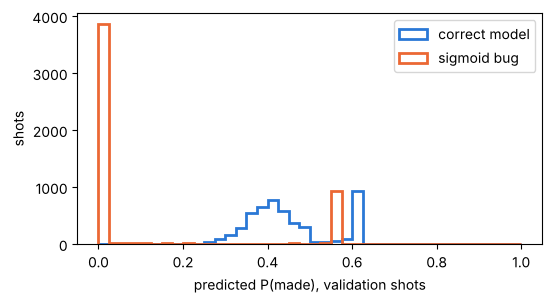

In [29]:
fig, ax = plt.subplots(figsize=(6, 3))
bins = np.linspace(0, 1, 41)
ax.hist(p_good.ravel(), bins=bins, histtype="step", lw=2, color="#2a78d6", label="correct model")
ax.hist(p_sig.ravel(), bins=bins, histtype="step", lw=2, color="#eb6834", label="sigmoid bug")
ax.set_xlabel("predicted P(made), validation shots")
ax.set_ylabel("shots")
ax.legend()
plt.show()

Why: `BCEWithLogitsLoss` applies **another** sigmoid. The model's output p is already in (0, 1), so the loss only ever sees σ(p):

In [30]:
torch.sigmoid(torch.tensor([0.0, 1.0]))        # the 'probability' the loss sees is stuck in (0.5, 0.73)

tensor([0.5000, 0.7311])

For a made shot the best loss it can reach is −log σ(1) = 0.313; for a miss, −log(1 − σ(0)) = 0.693. So the
printed loss always looks like "about 0.69", and the only way to lower it is to push p all the way to 0 or 1.
The model cannot say "40%". Karpathy's mistake #4: "you passed softmaxed outputs to a loss that expects raw logits".
**Fix:** either logits + `BCEWithLogitsLoss` (what we do), or `nn.Sigmoid()` + `nn.BCELoss` (the Kobe baseline's head). Never both sigmoids.

## Part 8 · Planned mistake 4: target shape `(N,)` vs `(N, 1)`

**PREDICT: what will happen?** The model outputs `(N, 1)` but the targets are `(N,)`.
With `BCEWithLogitsLoss`? With `MSELoss`?

In [31]:
logits = model(X_val_s[:5])                    # (5, 1)
target = y_val[:5].view(-1)                    # (5,)   <- MISTAKE 4: the column dimension is gone
print(logits.shape, target.shape)
try:                                           # try/except only so that "Run all" does not stop here
    loss_fn(logits, target)
except ValueError as err:
    print("ValueError:", err)

torch.Size([5, 1]) torch.Size([5])
ValueError: Target size (torch.Size([5])) must be the same as input size (torch.Size([5, 1]))


A loud error: read the message aloud, it says exactly what is wrong. `MSELoss` is quieter:

In [32]:
pred = torch.tensor([[1.0], [2.0], [3.0], [4.0], [5.0]])   # (5, 1): a PERFECT prediction ...
truth = torch.tensor([1.0, 2.0, 3.0, 4.0, 5.0])            # (5,)
print("MSE:", nn.MSELoss()(pred, truth).item())             # ... so this should be 0
print("pred - truth has shape", (pred - truth).shape)       # broadcasting: every prediction minus every target
print("fixed:", nn.MSELoss()(pred.squeeze(1), truth).item())

MSE: 4.0
pred - truth has shape torch.Size([5, 5])
fixed: 0.0


/usr/local/lib/python3.13/dist-packages/torch/nn/modules/loss.py:630: UserWarning: Using a target size (torch.Size([5])) that is different to the input size (torch.Size([5, 1])). This will likely lead to incorrect results due to broadcasting. Please ensure they have the same size.
  return F.mse_loss(input, target, reduction=self.reduction)


Only a warning, and a wrong number. This matters for the inversion task: `model(X)` returns `(1000, 1)` and
`y` is `(1000,)`. The `.squeeze()` in the starter code is what prevents a silent 1000 × 1000 loss.

## Part 9 · Optimizer comparison on Kobe

The same net, the same seed, 30 epochs; only the optimizer and its learning rate change.

**PREDICT (P8, P10):** rank SGD lr 1e-3, SGD lr 0.1, Adam lr 1e-3 and Adam lr 1.0.
Which ones end up no better than the constant 0.688?

In [33]:
rows = []
for opt_class, lr in [(torch.optim.SGD, 1e-3), (torch.optim.SGD, 0.1), (torch.optim.Adam, 1e-3), (torch.optim.Adam, 1.0)]:
    torch.manual_seed(0)
    m = MLP()
    train(m, opt_class(m.parameters(), lr=lr))
    loss, acc = evaluate(m, X_val_s, y_val)
    rows.append([opt_class.__name__, lr, loss, acc])
pd.DataFrame(rows, columns=["optimizer", "lr", "val log loss", "val accuracy"])

,optimizer,lr,val log loss,val accuracy
0,SGD,0.001,0.6824,0.5524
1,SGD,0.100,0.6644,0.6082
2,Adam,0.001,0.6641,0.6080
3,Adam,1.000,0.7003,0.5524


* SGD 1e-3 barely moves in 9,390 steps. SGD 0.1 is as good as Adam: tuned SGD is fine.
* Adam 1.0 jumps around and ends at "always miss".
* Adam 1e-3 reproduces part 5 exactly: same seed, same numbers.
* lr 1e-3 is an Adam default, not a law of nature: sweep 3e-4, 1e-3, 3e-3, 1e-2 and pick by validation loss.

## Part 10 · Overfitting and early stopping

Overfitting needs a big model and little data: a 2-256-256-1 trained on only **500** shots, full batch, Adam 1e-3,
2000 steps. Validation is the usual 5,000 shots.

**PREDICT:** sketch the train and validation loss curves.

In [34]:
torch.manual_seed(0)
few = torch.randperm(len(X_train_s))[:500]
X_few = X_train_s[few]
y_few = y_train[few]

big = MLP(hidden=256)
print("parameters:", sum(p.numel() for p in big.parameters()), "(the Kobe net has 105)")

parameters: 66817 (the Kobe net has 105)


In [35]:
import copy

opt = torch.optim.Adam(big.parameters(), lr=1e-3)
curve = []
best_val = float("inf")
for step in range(1, 2001):
    big.train()
    opt.zero_grad()
    loss = loss_fn(big(X_few), y_few)              # full batch: all 500 shots in every step
    loss.backward()
    opt.step()
    if step % 10 == 0:
        val = evaluate(big, X_val_s, y_val)[0]
        curve.append([step, loss.item(), val])
        if val < best_val:                         # early stopping: remember the best weights so far
            best_val = val
            best_step = step
            best_state = copy.deepcopy(big.state_dict())   # deepcopy! state_dict() alone shares memory with the live weights

curve = pd.DataFrame(curve, columns=["step", "train loss", "val loss"]).set_index("step")
curve.loc[[10, 100, 300, 1000, 2000]]

,train loss,val loss
step,,
10,0.6480,0.6752
100,0.6245,0.6801
300,0.5803,0.7186
1000,0.4685,0.8314
2000,0.3762,1.0125


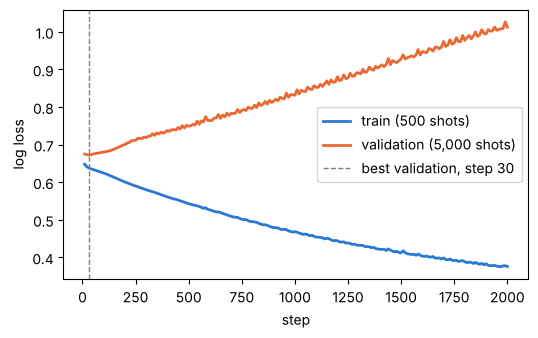

In [36]:
fig, ax = plt.subplots(figsize=(6, 3.5))
ax.plot(curve.index, curve["train loss"], color="#2a78d6", lw=2, label="train (500 shots)")
ax.plot(curve.index, curve["val loss"], color="#eb6834", lw=2, label="validation (5,000 shots)")
ax.axvline(best_step, color="0.5", ls="--", lw=1, label=f"best validation, step {best_step}")
ax.set_xlabel("step")
ax.set_ylabel("log loss")
ax.legend()
plt.show()

In [37]:
last_loss, last_acc = evaluate(big, X_val_s, y_val)
big.load_state_dict(best_state)                    # roll back to the best checkpoint
best_loss, best_acc = evaluate(big, X_val_s, y_val)
print(f"last weights (step 2000):  val log loss {last_loss:.4f}, accuracy {last_acc:.1%}")
print(f"best weights (step {best_step}):    val log loss {best_loss:.4f}, accuracy {best_acc:.1%}")

last weights (step 2000):  val log loss 1.0125, accuracy 55.6%
best weights (step 30):    val log loss 0.6727, accuracy 60.4%


Train loss keeps falling while validation loss climbs: the net memorises 500 noisy shots.
Cures: more data · a smaller model · weight decay · dropout · early stopping with the best checkpoint.
(Real early stopping also `break`s once validation has not improved for, say, 20 checks; we kept going only to draw the curve.)
For the 105-parameter Kobe net, overfitting is not the problem; optimisation is.

## Part 11 · Optimise the input, not the weights (bridge to the inversion task)

Training: the data is fixed and the weights move. Inversion: the model is frozen and an **input** moves.
The tools are the same: `requires_grad` on the unknown, a loss, an optimizer.
Toy model: f(a, b, c) = a + 2b + c². We know a = 1, c = 1.5 and the output y; recover b.

In [38]:
def f(a, b, c):                                # a frozen "model": we may only change what we feed it
    return a + 2 * b + c ** 2


a, c = 1.0, 1.5
y_seen = f(a, 0.7, c)                          # the true b is 0.7; from now on we only know y
b = torch.tensor(0.0, requires_grad=True)      # the unknown input is the thing we optimise
opt = torch.optim.SGD([b], lr=0.1)
for step in range(30):
    opt.zero_grad()
    loss = (f(a, b, c) - y_seen) ** 2
    loss.backward()
    opt.step()
print(f"y = {y_seen:.2f}   recovered b = {b.item():.4f}   loss = {loss.item():.1e}")

y = 4.65   recovered b = 0.7000   loss = 0.0e+00


**PREDICT:** the same with lr 0.125, 0.25 and 0.3?

In [39]:
for lr in [0.125, 0.25, 0.3]:
    b = torch.tensor(0.0, requires_grad=True)
    opt = torch.optim.SGD([b], lr=lr)
    path = []
    for step in range(6):
        opt.zero_grad()
        loss = (f(a, b, c) - y_seen) ** 2
        loss.backward()
        opt.step()
        path.append(round(b.item(), 3))
    print(f"lr {lr:<5}  b: {path}")

lr 0.125  b: [0.7, 0.7, 0.7, 0.7, 0.7, 0.7]
lr 0.25   b: [1.4, 0.0, 1.4, 0.0, 1.4, 0.0]
lr 0.3    b: [1.68, -0.672, 2.621, -1.989, 4.465, -4.571]


One step (lr = 1/8 is exactly Newton here) · bouncing forever · blowing up. The task has a whole column of
1,000 unknowns: one tensor, all rows at once. Adam moves each unknown by about lr per step, so lr 1e-3 is far
too slow for inputs of size ~1.

In [40]:
torch.manual_seed(0)
a_col = torch.randn(1000)
c_col = torch.randn(1000)
b_true = torch.randn(1000)                     # the column that was overwritten with 0.0
y_col = f(a_col, b_true, c_col)                # the frozen model's outputs: known

for lr in [1e-3, 0.1]:
    b_hat = torch.zeros(1000, requires_grad=True)          # start from the zeros in the file
    opt = torch.optim.Adam([b_hat], lr=lr)
    for step in range(300):
        opt.zero_grad()
        loss = ((f(a_col, b_hat, c_col) - y_col) ** 2).mean()    # (1000,) vs (1000,): no broadcasting trap
        loss.backward()
        opt.step()
    mse = ((b_hat - b_true) ** 2).mean().item()
    print(f"Adam lr {lr:<5}  300 steps:  MSE(recovered b, true b) = {mse:.4f}")

Adam lr 0.001  300 steps:  MSE(recovered b, true b) = 0.5656
Adam lr 0.1    300 steps:  MSE(recovered b, true b) = 0.0000


Not every unknown is this easy. If **c** is the missing input, c² = 2.25 has two answers:

In [41]:
for start in [0.1, -0.1, 0.0]:
    c_hat = torch.tensor(start, requires_grad=True)
    opt = torch.optim.SGD([c_hat], lr=0.05)
    for step in range(200):
        opt.zero_grad()
        loss = (f(a, 0.7, c_hat) - y_seen) ** 2
        loss.backward()
        opt.step()
    print(f"start {start:+.1f}  ->  c = {c_hat.item():+.4f}")

start +0.1  ->  c = +1.5000
start -0.1  ->  c = -1.5000
start +0.0  ->  c = +0.0000


The start decides which root you get, and starting exactly at 0 gets stuck: the gradient there is exactly 0.
In the real task: freeze the model (`model.eval()`, no weight changes), put `requires_grad` on the missing
column only, use `torch.cat` to rebuild the input, mind the `(1000, 1)` vs `(1000,)` shapes, and check the residual.

**Pre-flight checklist for both tasks:** seed · scale inputs with train statistics · loss at init ≈ 0.69 ·
baselines first · validation split · logits + `BCEWithLogitsLoss` · `zero_grad` · target shapes ·
Adam 1e-3, then sweep the lr · keep the best weights · assert the parameter count (≤ 105).